In [1]:
import torch
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn.functional as F
import random

In [44]:
words = open("names.txt" ,'r').read().splitlines()
len(words)

32033

In [45]:
#vocaublary from words
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] =0
itos = {i:s for s,i in stoi.items()}
itos
voab_size = len(stoi)
print(voab_size)

27


In [72]:
block_size =3
def build_dataset(words):
    X,Y=[],[]

    for w in words:
        context = [0]*block_size       
        for i in w+'.':
            X.append([i for i in context])
            Y.append(stoi[i])
            context = context[1:]+[stoi[i]]
    
    x= torch.tensor(X)
    y=torch.tensor(Y)
    return x,y


# x,y =build_dataset(words[:3])
# print(x)
# print(len(y))   
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

xtr , ytr = build_dataset(words[:n1]) 
xval , yval = build_dataset(words[n1:n2]) 
xtest , ytest = build_dataset(words[n2:])     
        
    

In [ ]:
n_embd =10 # dimension of embedding 
n_hidden =200 # neuron in hidden layer

g= torch.Generator().manual_seed(2147483647)
C = torch.randn((voab_size,n_embd) , generator=g)

w1 = torch.randn((n_embd*block_size,n_hidden) , generator=g )*(5/3)/(n_embd*block_size)**0.5
b1 = torch.randn(n_hidden , generator=g ) * 0.01
w2 = torch.randn((n_hidden,voab_size) , generator=g)*0.01
b2 = torch.randn(voab_size , generator=g )*0

bngain = torch.ones((1,n_hidden))
bnbias = torch.zeros((1,n_hidden))

bnmean_running = torch.zeros((1,n_hidden))
bnstd_running = torch.zeros((1,n_hidden))

parameters = [C,w1,w2,b1,b2 , bnbias,bnbias]
number_of_parameters = sum(p.nelement() for p in parameters)
print(number_of_parameters)
for p in parameters:
    p.requires_grad =True
    
w1.shape

12297


torch.Size([30, 200])

In [ ]:
max_step = 200000
batch_size =32 
lossi =[]
for i in range(max_step):
    ix = torch.randint(0,xtr.shape[0],(batch_size,),generator=g)
    xb,yb = xtr[ix],ytr[ix]
    # forward pass
    embd = C[xb]
    embd_cat = embd.view(embd.shape[0],-1)
    hpreact = embd_cat @ w1 +b1
    #batch normilation
    bnmean =hpreact.mean(dim=0 ,keepdim=True)
    bnstd =hpreact.std(dim=0 ,keepdim=True)
    hpreact = bngain *((hpreact -bnmean)/bnstd) + bnbias    
    
    h = torch.tanh(hpreact)
    logits = h@w2+b2
    loss  = F.cross_entropy(logits,yb)
    
    with torch.no_grad():
        bnmean_running = 0.999*bnmean_running + 0.001*bnmean
        bnstd_running = 0.999*bnstd_running + 0.001*bnstd
    
    for p in parameters:
        p.grad = None
    loss.backward()
    lr = 0.1 if i< 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad
    
    if i % 10000 ==0:
        print(f'{i}/{max_step}->  loss: {loss.item()}')
    lossi.append(loss.log10().item())

    
    
    

0/200000->  loss: 3.2982261180877686


10000/200000->  loss: 2.2031986713409424
20000/200000->  loss: 2.114154100418091
30000/200000->  loss: 1.997322678565979
40000/200000->  loss: 2.230539560317993
50000/200000->  loss: 2.0833699703216553
60000/200000->  loss: 2.1789612770080566
70000/200000->  loss: 1.9067790508270264
80000/200000->  loss: 2.8644180297851562
90000/200000->  loss: 2.08162260055542
100000/200000->  loss: 2.025571346282959
110000/200000->  loss: 1.9756077527999878
120000/200000->  loss: 2.151503562927246
130000/200000->  loss: 2.0319886207580566
140000/200000->  loss: 1.8448853492736816
150000/200000->  loss: 2.3705806732177734
160000/200000->  loss: 1.8838880062103271
170000/200000->  loss: 2.1367204189300537
180000/200000->  loss: 2.157531499862671
190000/200000->  loss: 1.914635419845581


In [ ]:
# hpreact.mean(dim=0 ,keepdim=True).shape
# hpreact.std(dim=0 ,keepdim=True).shape
# hpreact.shape

torch.Size([32, 200])

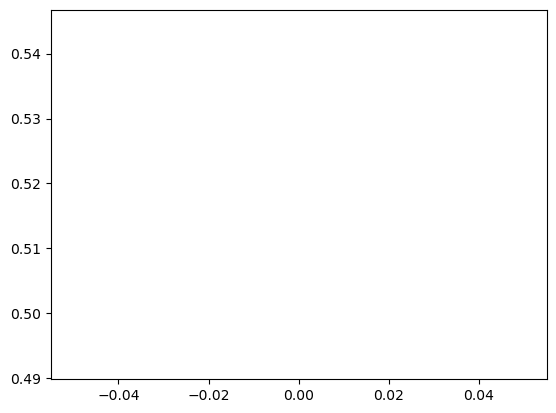

In [115]:
plt.plot(lossi)

In [ ]:
@torch.no_grad()
def split_loss(split):
    x,y ={
        'train':(xtr,ytr)
        ,'val': (xval,yval)
        ,'test': (xtest,ytest)
    }[split]
    embd = C[x]
    embd_cat  = embd.view(embd.shape[0],-1)
    hpreact = embd_cat @ w1 +b1
    hpreact = bngain *((hpreact -bnmean_running)/bnstd_running) + bnbias 

    h = torch.tanh(hpreact)
    logits = h@w2+b2
    loss  = F.cross_entropy(logits,y)
    print(split ,loss.item())
    
split_loss("train") 
split_loss("val") 

train 3.280442714691162
val 3.2810730934143066


In [ ]:

g= torch.Generator().manual_seed(2147483647+10)

for _ in range(20):
    out  =[]
    context =[0]*block_size
    while True:
        embd = C[torch.tensor(context)]
        # print(embd.shape)
        embd_cat  = embd.view(1,-1)
        hpreact = embd_cat @ w1 +b1
        hpreact = bngain *((hpreact -bnmean_running)/bnstd_running) + bnbias 

        h = torch.tanh(hpreact)
        logits = h@w2+b2
        probs = F.softmax(logits,dim=1)
        ix = torch.multinomial(probs,num_samples=1,generator=g).item()
        out.append(itos[ix])
        context=context[1:]+[ix]
        if ix ==0: 
            break
    print(''.join([i for i in out]))

        
        
            



/tmp/ipykernel_21348/3177347642.py:11: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1879.)
  hpreact = bngain *((hpreact -hpreact.mean(dim=0 ,keepdim=True))/hpreact.std(dim=0 ,keepdim=True)) + bnbias


RuntimeError: probability tensor contains either `inf`, `nan` or element < 0